In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

##  Multiple Linear Regression from scratch using OLS

In [37]:
class MultipleLinearRegressionOLS:

    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
    
    def fit(self, X: np.ndarray, y: np.ndarray):

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        
        if y.ndim != 1:
            raise ValueError("y must be a 1D array.")
        
        if X.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of samples.")
        
        # Add a column of ones to learn the intercept.
        X_with_bias = np.column_stack((np.ones(X.shape[0]), X))

        betas = np.linalg.inv(X_with_bias.T @ X_with_bias) @ X_with_bias.T @ y

        self.intercept_ = betas[0]
        self.coef_ = betas[1:]
    
    def predict(self, X: np.ndarray):

        if self.coef_ is None or self.intercept_ is None:
            raise ValueError("Model must be fitted before making predictions.")
        
        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        
        if X.shape[1] != self.coef_.shape[0]:
            raise ValueError("X must contain the same number of features used during training.")
        
        return X @ self.coef_ + self.intercept_

In [23]:
# Load the diabetes dataset

diabetes = load_diabetes()
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [24]:
X = diabetes.data
y = diabetes.target

feature_names = diabetes.feature_names

In [25]:
X.shape, y.shape

((442, 10), (442,))

In [26]:
feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

In [27]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [28]:
len(X_train), len(X_test)

(353, 89)

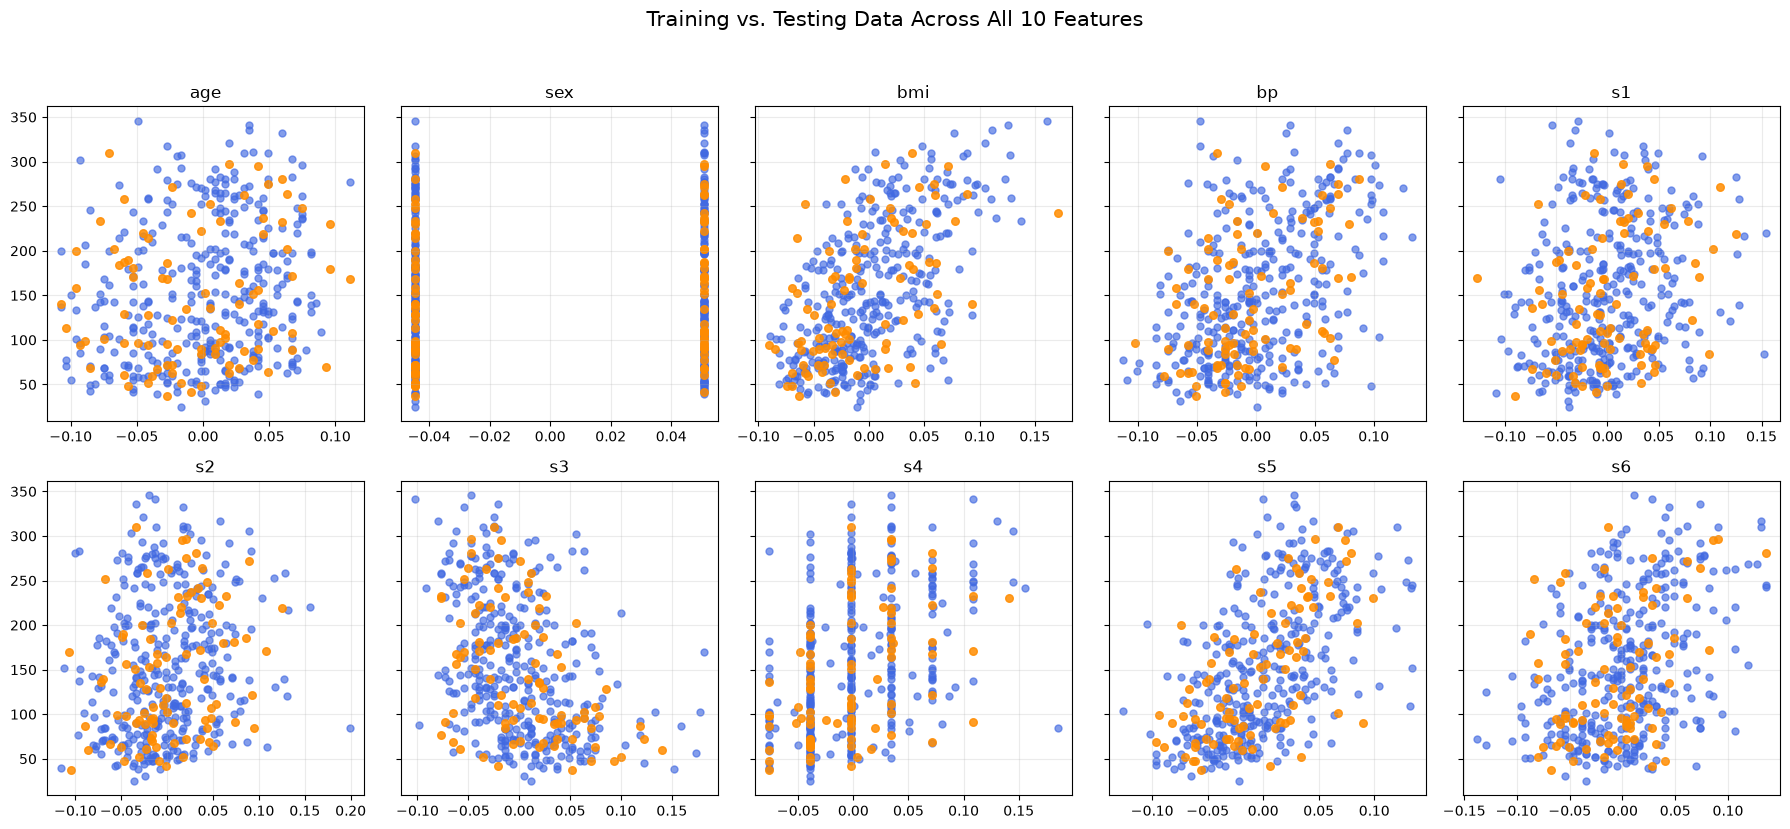

In [33]:
# Visualize training and testing data

fig, axes = plt.subplots(nrows=2,ncols=5,figsize=(18, 8),sharey=True)

for i, ax in enumerate(axes.flat):
    ax.scatter(X_train[:, i],y_train,color="royalblue",alpha=0.65,s=25,label="Training Data")
    ax.scatter(X_test[:, i],y_test,color="darkorange",alpha=0.85,s=30,label="Testing Data")

    ax.set_title(feature_names[i])
    ax.grid(alpha=0.25)

fig.suptitle("Training vs. Testing Data Across All 10 Features",fontsize=15,y=1.03,)

plt.tight_layout()
plt.show()

In [38]:
# Train the model

mlr_ols = MultipleLinearRegressionOLS()

mlr_ols.fit(X_train, y_train)

In [39]:
mlr_ols.coef_

array([  37.90402135, -241.96436231,  542.42875852,  347.70384391,
       -931.48884588,  518.06227698,  163.41998299,  275.31790158,
        736.1988589 ,   48.67065743])

In [40]:
mlr_ols.intercept_

np.float64(151.34560453985998)

In [42]:
for name, coef in zip(feature_names, mlr_ols.coef_):
    print(f"{name:>5}: {coef:10.4f}")

  age:    37.9040
  sex:  -241.9644
  bmi:   542.4288
   bp:   347.7038
   s1:  -931.4888
   s2:   518.0623
   s3:   163.4200
   s4:   275.3179
   s5:   736.1989
   s6:    48.6707


In [44]:
equation = f"y = {mlr_ols.intercept_:.4f}" + "".join(f" + ({coef:.4f} * {name})"for name, coef in zip(feature_names, mlr_ols.coef_))

print(equation)

y = 151.3456 + (37.9040 * age) + (-241.9644 * sex) + (542.4288 * bmi) + (347.7038 * bp) + (-931.4888 * s1) + (518.0623 * s2) + (163.4200 * s3) + (275.3179 * s4) + (736.1989 * s5) + (48.6707 * s6)


In [45]:
# Make predictions on the test data

y_pred = mlr_ols.predict(X_test)

In [46]:
y_pred[:10]

array([139.5475584 , 179.51720835, 134.03875572, 291.41702925,
       123.78965872,  92.1723465 , 258.23238899, 181.33732057,
        90.22411311, 108.63375858])

In [47]:
# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


MAE:  42.7941
MSE:  2900.1936
RMSE: 53.8534
R²:   0.4526
